In [40]:
#
# synthetic_net.py
#
# SYNTHETIC URBAN DISTRICT GENERATOR
#
# Generates a procedural synthetic urban district with orthogonal
# street grid (single centreline per street) and building allocation
# on internal block frontages.
#
# This module is shared across all TG and SC benchmark archetypes.
# It provides only the district geometry and street graph —
# network topology and pipe parameters are defined in each
# archetype file (e.g. DHN_TG_3G_M_M_BASE.py).
#

In [41]:
import math
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from networkx.algorithms.approximation import steiner_tree

In [42]:
# =====================================================================
# 1. DISTRICT GENERATOR
# =====================================================================
class DistrictGenerator:
    """
    Generates a synthetic urban district grid where roads are modelled as
    single-line centrelines to avoid double-pipe routing artefacts.

    Parameters
    ----------
    width, height    : footprint dimensions [m]
    rows, cols       : number of block rows/columns
    street_width     : uniform street width [m]
    n_substations    : total number of consumer substations
    block_variation  : relative variation of block dimensions (±fraction)
    perturbation     : max jitter on building position along frontage [m]
    seed             : random seed for full reproducibility
    """

    def __init__(self, width=1200, height=800, rows=5, cols=7,
                 street_width=15, n_substations=100,
                 block_variation=0.12, perturbation=5, seed=42):
        self.width           = width
        self.height          = height
        self.rows            = rows
        self.cols            = cols
        self.street_width    = street_width
        self.n_substations   = n_substations
        self.block_variation = block_variation
        self.perturbation    = perturbation
        self.seed            = seed

        random.seed(seed)
        self.blocks       = []
        self.buildings    = []
        self.street_nodes = {}
        self.street_edges = []
        self.street_graph = nx.Graph()

    # ------------------------------------------------------------------
    def random_partition(self, total, n):
        mean   = total / n
        values = [mean * (1 + random.uniform(-self.block_variation,
                                              self.block_variation))
                  for _ in range(n)]
        scale  = total / sum(values)
        values = [v * scale for v in values]
        values[-1] = total - sum(values[:-1])
        return values

    # ------------------------------------------------------------------
    def build_street_grid(self):
        usable_w = self.width  - (self.cols + 1) * self.street_width
        usable_h = self.height - (self.rows  + 1) * self.street_width

        self.block_widths  = self.random_partition(usable_w, self.cols)
        self.block_heights = self.random_partition(usable_h, self.rows)

        # Block boundary coordinates
        self.x = [0]
        for bw in self.block_widths:
            self.x.append(self.x[-1] + self.street_width)
            self.x.append(self.x[-1] + bw)

        self.y = [0]
        for bh in self.block_heights:
            self.y.append(self.y[-1] + self.street_width)
            self.y.append(self.y[-1] + bh)

        # Street centreline coordinates
        cx = [(self.x[i] + self.x[i+1]) / 2 if i+1 < len(self.x)
              else self.x[i] for i in range(0, len(self.x), 2)]
        cy = [(self.y[j] + self.y[j+1]) / 2 if j+1 < len(self.y)
              else self.y[j] for j in range(0, len(self.y), 2)]

        for i, x in enumerate(cx):
            for j, y in enumerate(cy):
                self.street_nodes[(i, j)] = (x, y)

        for i in range(len(cx) - 1):
            for j in range(len(cy)):
                self.street_edges.append(((i, j), (i+1, j)))
        for i in range(len(cx)):
            for j in range(len(cy) - 1):
                self.street_edges.append(((i, j), (i, j+1)))

        for node, pos in self.street_nodes.items():
            self.street_graph.add_node(node, pos=pos)
        for n1, n2 in self.street_edges:
            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]
            self.street_graph.add_edge(n1, n2,
                                       length=abs(x2-x1)+abs(y2-y1))

    # ------------------------------------------------------------------
    def build_blocks(self):
        block_id = 0
        for c in range(self.cols):
            for r in range(self.rows):
                x0 = self.x[2*c + 1]
                y0 = self.y[2*r + 1]
                self.blocks.append({
                    "id": block_id, "x": x0, "y": y0,
                    "col": c, "row": r,
                    "width":  self.block_widths[c],
                    "height": self.block_heights[r],
                    "area":   self.block_widths[c] * self.block_heights[r],
                })
                block_id += 1

    # ------------------------------------------------------------------
    def build_buildings(self):
        building_id = 0
        block_index = 0
        MARGIN  = self.street_width * 0.5
        MIN_GAP = 15.0

        for c in range(self.cols):
            for r in range(self.rows):
                block = self.blocks[block_index]
                x0, y0 = block["x"], block["y"]
                bw, bh  = block["width"], block["height"]

                available = []
                if r < self.rows - 1: available.append("N")
                if r > 0:             available.append("S")
                if c < self.cols - 1: available.append("E")
                if c > 0:             available.append("W")

                if not available:
                    block_index += 1
                    continue

                n = self._allocation[block_index]
                front_lens   = {"N": bw, "S": bw, "E": bh, "W": bh}
                avail_lens   = {s: front_lens[s] for s in available}
                total_len    = sum(avail_lens.values())
                sides_sorted = sorted(avail_lens, key=avail_lens.get,
                                      reverse=True)
                front_counts = {}
                assigned     = 0
                for i, side in enumerate(sides_sorted):
                    if i == len(sides_sorted) - 1:
                        front_counts[side] = n - assigned
                    else:
                        cnt = max(0, round(n * avail_lens[side] / total_len))
                        front_counts[side] = cnt
                        assigned += cnt

                for side, cnt in front_counts.items():
                    if cnt <= 0:
                        continue
                    if side in ("N", "S"):
                        axis_len, axis_start = bw, x0
                        fixed = y0 + bh - MARGIN if side == "N" \
                                else y0 + MARGIN
                    else:
                        axis_len, axis_start = bh, y0
                        fixed = x0 + bw - MARGIN if side == "E" \
                                else x0 + MARGIN

                    spacing = max(axis_len / (cnt + 1), MIN_GAP)
                    for k in range(cnt):
                        pos = axis_start + spacing * (k + 1)
                        pos += random.uniform(-self.perturbation,
                                              self.perturbation)
                        pos = max(axis_start + MIN_GAP,
                                  min(axis_start + axis_len - MIN_GAP, pos))
                        bx, by = (pos, fixed) if side in ("N", "S") \
                                  else (fixed, pos)
                        self.buildings.append({
                            "id": building_id,
                            "x": bx, "y": by,
                            "block": block["id"],
                        })
                        building_id += 1
                block_index += 1

    # ------------------------------------------------------------------
    def generate(self):
        self.build_street_grid()
        self.build_blocks()

        n_blocks    = len(self.blocks)
        avail_cnts  = []
        for idx in range(n_blocks):
            c, r = idx // self.rows, idx % self.rows
            cnt  = sum([r < self.rows-1, r > 0,
                        c < self.cols-1, c > 0])
            avail_cnts.append(max(cnt, 1))

        total_avail = sum(avail_cnts)
        raw         = [self.n_substations * a / total_avail
                       for a in avail_cnts]
        allocation  = [max(1, round(v)) for v in raw]
        diff        = self.n_substations - sum(allocation)
        for i in range(abs(diff)):
            allocation[i % n_blocks] += 1 if diff > 0 else -1
            allocation[i % n_blocks]  = max(0, allocation[i % n_blocks])

        self._allocation = allocation
        self.build_buildings()
        return self

    # ------------------------------------------------------------------
    def plot_district(self, ax=None, show=True):
        if ax is None:
            fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')
        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, b in enumerate(self.blocks):
            ax.add_patch(patches.Rectangle(
                (b["x"], b["y"]), b["width"], b["height"],
                facecolor=colors[idx % len(colors)],
                edgecolor='none', zorder=1))
        xs = [b["x"] for b in self.buildings]
        ys = [b["y"] for b in self.buildings]
        ax.scatter(xs, ys, color='#CC2200', s=50, marker='s',
                   edgecolors='white', linewidths=0.4, zorder=5,
                   label='Substations')
        ax.set_xlim(-20, self.width+20)
        ax.set_ylim(-20, self.height+20)
        ax.set_title("Synthetic Urban District", fontweight="bold", fontsize=12)
        ax.set_aspect('equal'); ax.axis('off')
        if show:
            plt.tight_layout(); plt.show()

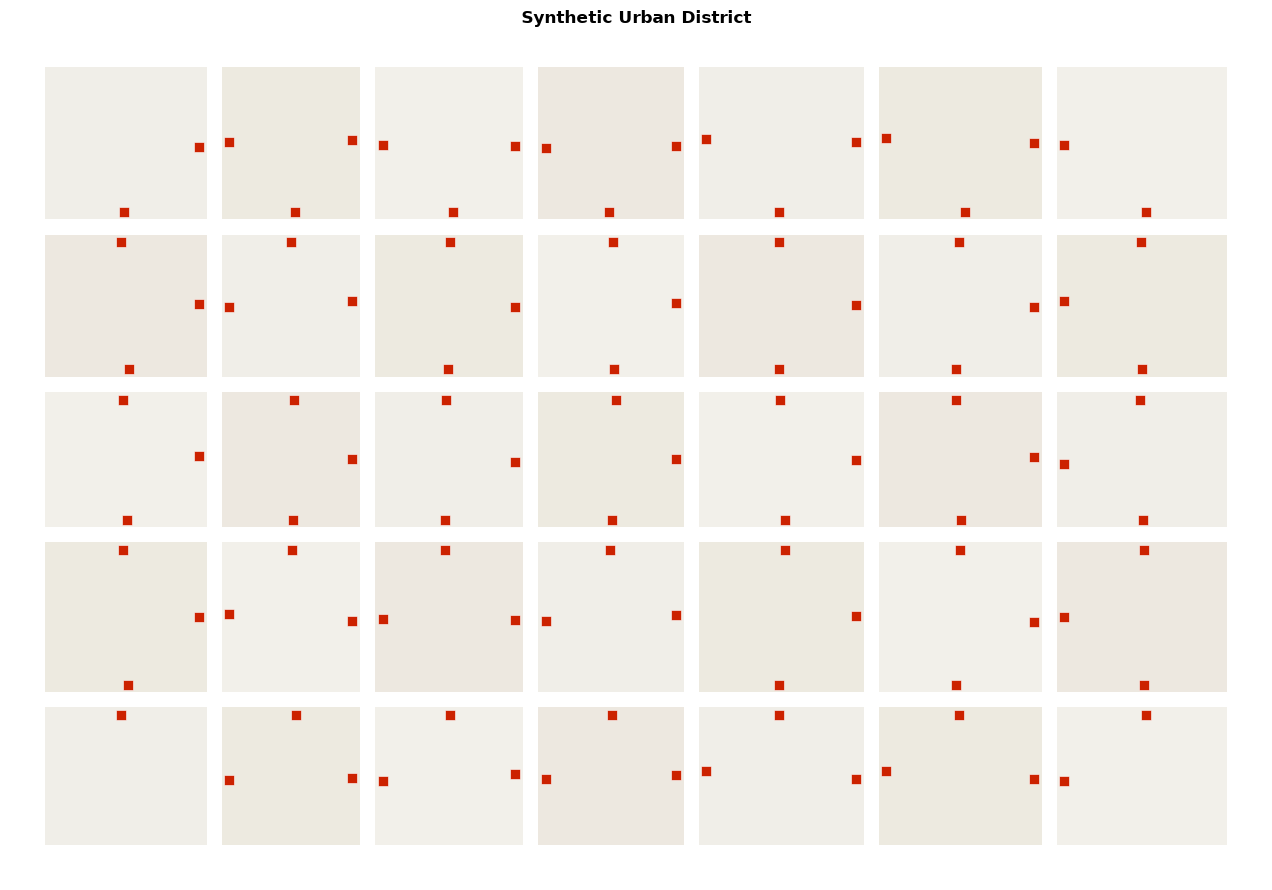

In [43]:
district = DistrictGenerator()
district.generate()
district.plot_district()

In [44]:
# =====================================================================
# 2. NETWORK BUILDER (Steiner Tree + Parametric Meshing)
# =====================================================================
class ThermalNetworkBuilder:
    """
    Constructs an optimized District Heating Network benchmark using
    Steiner Tree approximation, followed by controlled loop/mesh injections.
    """

    def __init__(self, district):
        self.district = district
        self.network_graph = district.street_graph.copy()
        self.terminals = []
        self.plant_node = None
        self.projection_to_building = {}
        self.main_network = None
        self.branch_pipes = []

    def _project_point_on_segment(self, px, py, x1, y1, x2, y2):
        """Orthogonally projects a substation point onto a centerline road segment."""
        dx, dy = x2 - x1, y2 - y1
        if dx == 0 and dy == 0: return x1, y1, 0.0
        t = max(0.0, min(1.0, ((px - x1) * dx + (py - y1) * dy) / (dx * dx + dy * dy)))
        proj_x, proj_y = x1 + t * dx, y1 + t * dy
        return proj_x, proj_y, ((px - proj_x) ** 2 + (py - proj_y) ** 2) ** 0.5

    def build_network(self, plant_position=(0, 0)):
        """
        Calculates the baseline tree topology by introducing orthogonal projection
        nodes directly into the centerline graph and running a Steiner Tree.
        """
        self.plant_node = plant_position
        self.terminals.append(self.plant_node)

        # Project substations onto the closest centerline street segment
        for building in self.district.buildings:
            bx, by = building["x"], building["y"]
            best_edge, min_dist, best_proj = None, float("inf"), (0, 0)

            for u, v in self.network_graph.edges():
                pos_u, pos_v = self.network_graph.nodes[u]["pos"], self.network_graph.nodes[v]["pos"]
                px, py, d = self._project_point_on_segment(bx, by, pos_u[0], pos_u[1], pos_v[0], pos_v[1])
                if d < min_dist:
                    min_dist, best_proj, best_edge = d, (px, py), (u, v)

            # Split the chosen road edge to insert a structural projection junction node
            proj_node_id = f"proj_b_{building['id']}"
            u, v = best_edge
            pos_u, pos_v = self.network_graph.nodes[u]["pos"], self.network_graph.nodes[v]["pos"]
            len_u = abs(best_proj[0] - pos_u[0]) + abs(best_proj[1] - pos_u[1])
            len_v = abs(pos_v[0] - best_proj[0]) + abs(pos_v[1] - best_proj[1])

            if self.network_graph.has_edge(u, v):
                self.network_graph.remove_edge(u, v)

            self.network_graph.add_node(proj_node_id, pos=best_proj)
            self.network_graph.add_edge(u, proj_node_id, length=len_u)
            self.network_graph.add_edge(proj_node_id, v, length=len_v)

            # This projection node becomes a required terminal for the network backbone
            self.terminals.append(proj_node_id)
            self.projection_to_building[proj_node_id] = building

        # Generate baseline Steiner Tree (returns a frozen NetworkX graph)
        self.main_network = steiner_tree(self.network_graph, self.terminals, weight='length')

    def add_mesh_layers(self, max_extra_edges=5):
        """
        Unfreezes the graph and adds structural loops/meshes by re-activating
        the shortest unused street axes that bridge existing active branches.
        """
        if self.main_network is None:
            raise ValueError("Baseline network must be built before injecting meshes.")

        # Convert frozen graph to a mutable instance
        self.main_network = nx.Graph(self.main_network)

        # Find all street segments left out by the Steiner Tree algorithm
        unused_edges = []
        for u, v, data in self.network_graph.edges(data=True):
            if not self.main_network.has_edge(u, v):
                unused_edges.append((u, v, data.get('length', 1.0)))

        # Sort unused edges by length to prioritize cost-effective mesh closures
        unused_edges.sort(key=lambda x: x[2])
        edges_added = 0

        for u, v, length in unused_edges:
            if edges_added >= max_extra_edges:
                break
            # Only connect if both endpoints are already part of the active backbone
            if u in self.main_network.nodes() and v in self.main_network.nodes():
                self.main_network.add_edge(u, v, length=length)
                edges_added += 1

        # Populate branch connection line segments (from centerline main pipe to building)
        self.branch_pipes = []
        for node in self.main_network.nodes():
            if node in self.projection_to_building:
                b = self.projection_to_building[node]
                self.branch_pipes.append({
                    "from_pos": self.network_graph.nodes[node]["pos"],
                    "to_pos": (b["x"], b["y"])
                })

        print(f"Meshing successful: {edges_added} loop-closure edges added to the TG benchmark.")

    def plot_network(self):
        fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')

        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, block in enumerate(self.district.blocks):
            ax.add_patch(patches.Rectangle(
                (block["x"], block["y"]), block["width"], block["height"],
                facecolor=colors[idx % len(colors)], edgecolor='none', zorder=1
            ))

        for n1, n2 in self.district.street_edges:
            pass

        # 1. Distribution line
        edges_list = list(self.main_network.edges())
        for u, v in edges_list:
            pos_u = self.network_graph.nodes[u]["pos"]
            pos_v = self.network_graph.nodes[v]["pos"]
            is_first = (u == edges_list[0][0] and v == edges_list[0][1])
            ax.plot([pos_u[0], pos_v[0]], [pos_u[1], pos_v[1]],
                    color='#FF8C00', lw=3, label='Distribution Network' if is_first else "", zorder=3)

        # 2. Building branches
        for i, pipe in enumerate(self.branch_pipes):
            p1, p2 = pipe["from_pos"], pipe["to_pos"]
            ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
                    color='#FF8C00', lw=1.5, linestyle='-', label='Buildings Branch' if i == 0 else "", zorder=4)

        # Buildings
        xs = [b["x"] for b in self.district.buildings]
        ys = [b["y"] for b in self.district.buildings]
        ax.scatter(xs, ys, color='#CC2200', s=50, zorder=5, marker='s', edgecolors='white', linewidths=0.4, label='Buildings')

        # Source
        plant_pos = self.network_graph.nodes[self.plant_node]["pos"]
        ax.scatter(plant_pos[0], plant_pos[1], color='#660000', s=250, marker='o', edgecolors='white', linewidths=1, label='Source', zorder=6)

        ax.set_xlim(-20, self.district.width + 20)
        ax.set_ylim(-20, self.district.height + 20)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.legend(loc='lower center', frameon=True, facecolor='white', edgecolor='none')

        plt.tight_layout()
        plt.show()

Meshing successful: 6 loop-closure edges added to the TG benchmark.


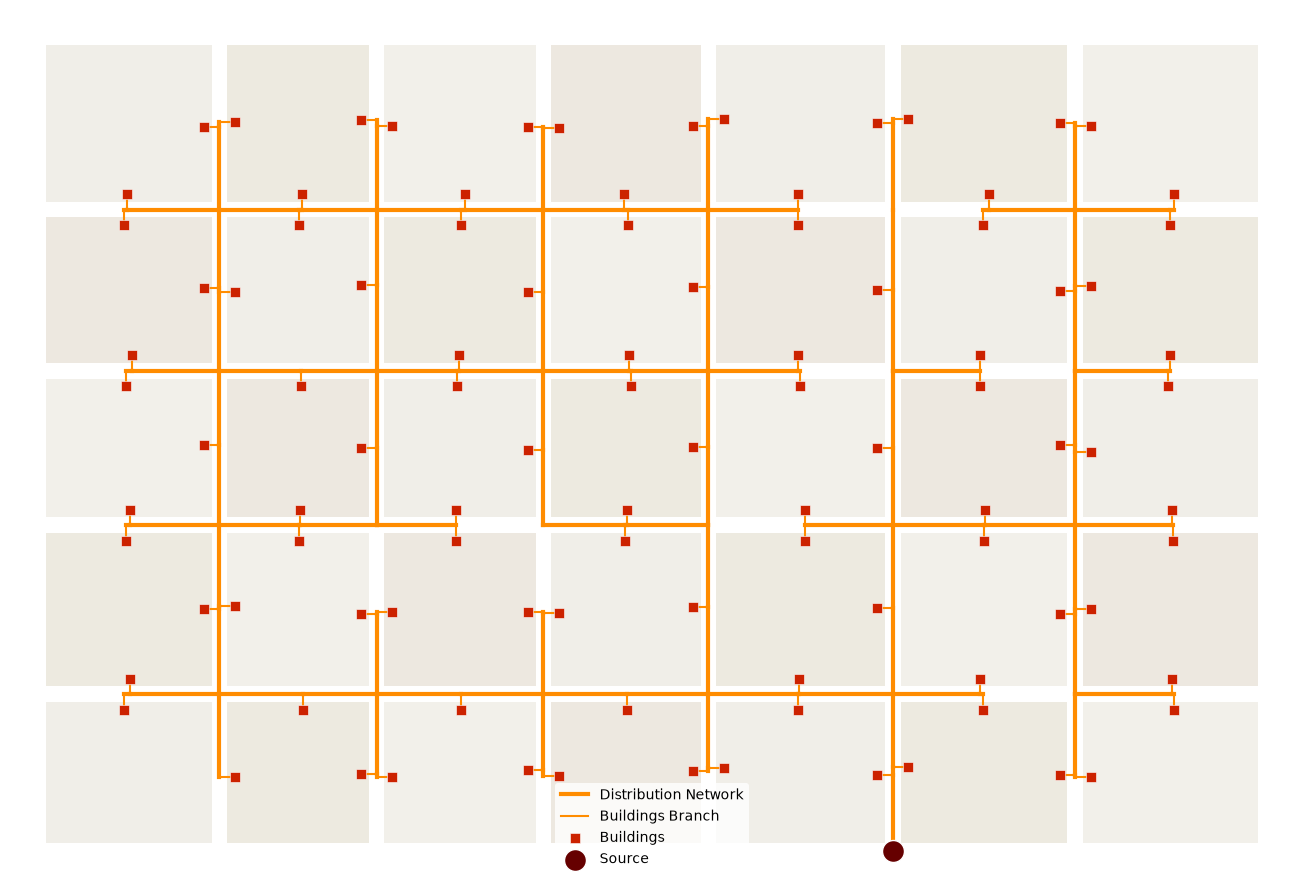

In [46]:
builder = ThermalNetworkBuilder(district)

builder.build_network(plant_position=(5, 0))
builder.add_mesh_layers(max_extra_edges=6)

builder.plot_network()